# Prelim

## Imports, Basic Data Check

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from typing import Optional, Union
import time
from tqdm.notebook import tqdm 

In [72]:
col_names = ["flow", "agent_ip", "src_port", "dst_port", "src_mac", "dst_mac", "ethernet_type", "dst_vlan", "src_vlan", "src_ip", "dst_ip", "tcp6_udp17", "ip_type_of_service", "ip_time_to_live", "src_port_transport_level", "dst_port_transport_level", "tcp_flags", "packet_size", "ip_size", "sampling_rate"]
df_data_2 = pd.read_csv("./Data/Data_2.csv", names = col_names, dtype= str)
df_test_SFlow = pd.read_csv("./Data/test_SFLow_data.csv", names = col_names, dtype= str)

In [73]:
display(df_data_2.head())
display(df_test_SFlow.head())
print("df data shape", df_data_2.shape)
print("df test shape", df_test_SFlow.shape)

,flow,agent_ip,src_port,dst_port,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,src_ip,dst_ip,tcp6_udp17,ip_type_of_service,ip_time_to_live,src_port_transport_level,dst_port_transport_level,tcp_flags,packet_size,ip_size,sampling_rate
0,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,74.125.10.59,137.132.38.238,17,0x00,63,443,62758,0x00,1396,1378,2048
1,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,173.194.22.215,137.132.228.29,6,0x00,63,443,39740,0x10,1438,1420,2048
2,FLOW,203.30.38.251,199,131,544b8cf9a7df,001cb0c88e40,0x0800,600,43,193.62.193.9,202.130.56.153,6,0x00,246,80,35794,0x18,272,250,2048
3,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919,43,74.125.130.132,192.122.131.33,6,0x00,52,443,5287,0x10,1418,1400,2048
4,FLOW,203.30.38.251,129,193,00135f21bc80,0031466b23cf,0x0800,11,919,155.69.160.69,74.125.68.139,17,0x60,59,48361,443,0x00,89,67,2048


,flow,agent_ip,src_port,dst_port,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,src_ip,dst_ip,tcp6_udp17,ip_type_of_service,ip_time_to_live,src_port_transport_level,dst_port_transport_level,tcp_flags,packet_size,ip_size,sampling_rate
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN


df data shape (177232, 20)
df test shape (1200, 20)


## Utils

### Ports

In [74]:
PORT_APP_MAP = {
    1: "OBSCURE: TCP Port Service Multiplexer",
    2: "OBSCURE: Compressnet's management utility, a obsolete protocol",
    3: "compressnet", # OBSCURE, a obsolete protocol
    6: "NOT FOUND",
    11: "OBSCURE: Active Users",
    12: "OBSCURE: Dark Ages of Camelot (game) / NOT FOUND",
    14: "NOT FOUND",
    18: "OBSCURE: Message Send Protocol",
    19: "OBSCURE: Character Generator",
    20: "ftp", #FTP data
    21: "FTP-Control",
    22: "SSH",
    23: "OBSCURE: Telnet",
    25: "SMTP",
    53: "DNS",
    67: "DHCP-Server",
    68: "DHCP-Client",
    80: "HTTP",
    110: "POP3",
    123: "NTP",
    129: "OBSCURE: Password Generator Protocol",
    130: "cisco-fna", # OBSCURE
    131: "OBSCURE: cisco network control/management traffic",
    133: "OBSCURE: Farnaz Statistics Service",
    134: "OBSCURE: INGRES-NET Service",
    135: "OBSCURE: Remote Procedure Call",
    136: "OBSCURE: PROFILE Naming System",
    138: "OBSCURE: NETBIOS Name Service",
    143: "IMAP",
    161: "SNMP",
    193: "srmp", # OBSCURE
    195: "OBSCURE: DNSIX Network Level Module Audit",
    199: "smux", # OBSCURE, https://www.speedguide.net/port.php?port=199 say also by CISCO
    200: "OBSCURE: IBM System Resource Controller",
    256: "OBSCURE: RAP (TCP/UDP)",
    443: "HTTPS",
    445: "SMB",
    3306: "MySQL",
    5432: "PostgreSQL",
    6379: "Redis",
    8080: "HTTP-Alt",
    1073741823: "OBSCURE: VPN or similar"
}


### Graphing

In [ ]:
def draw_1_var_bar_chart(
    field_name,
    df,
    top_n: int = 5,
    ax=None,
    rot=45,
    aggregated: bool = False,
    count_col: Optional[str] = None,
    color: str = "tab:blue",
    title: Optional[str] = None
):
    """
    Draw a top-N bar chart for a single column in df, with counts and percentage labels.

    Parameters:
        field_name (str): Column name to plot.
        df (pd.DataFrame): The DataFrame containing the data.
        top_n (int): Number of top categories to display.
        ax (matplotlib.axes.Axes): Optional, axes to plot on.
        rot (int): Rotation of x-axis tick labels.
        aggregated (bool): 
            - False: compute value counts on `field_name`. 
            - True: assume `df` already contains counts in `count_col`.
        count_col (str): Name of the column that contains counts if `aggregated=True`.
        color (str): Color of the bars.
        title (str): Custom title for the chart. If None, defaults to "Top {top_n} {field_name}".
    """
    if field_name not in df.columns:
        raise ValueError(f"{field_name} is not in df columns")
    
    # Handle aggregated vs non-aggregated
    if aggregated:
        if count_col is None or count_col not in df.columns:
            raise ValueError("When aggregated=True, a valid count_col must be provided")
        freq_df = df[[field_name, count_col]].copy()
        freq_df.columns = [field_name, "frequency"]
    else:
        freq_df = df[field_name].value_counts().reset_index()
        freq_df.columns = [field_name, "frequency"]
    
    total = freq_df["frequency"].sum()
    
    # Create axes if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    
    bar = freq_df.head(top_n).plot(
        kind="bar",
        x=field_name,
        y=count_col if count_col else "frequency",
        legend=False,
        ax=ax,
        color=color
    )
    
    ax.set_title(title if title else f"Top {top_n} {field_name}")
    ax.set_xlabel(field_name)
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=rot)
    ax.margins(y=0.3)
    
    labels = [
        f"{count}\n{count / total * 100:.1f}%"
        for count in freq_df.head(top_n)["frequency"]
    ]
    ax.bar_label(bar.containers[0], labels=labels, label_type="edge", padding=3, fontsize=9)
    
    return ax


### IP & organisations

In [76]:
def get_ip_details(
    ip: Union[str, pd.Series],
    get_organisation: bool = False,
    delay: float = 1.0,
    max_retries: int = 3
) -> Union[Optional[str], pd.Series]:
    """
    Fetch IP details from ipinfo.io.
    
    Args:
        ip: A single IP (str) or a pandas Series of IPs.
        get_organisation: If True, returns 'org' field only.
        delay: Delay (seconds) between requests to avoid rate limits.
        max_retries: Number of retries on request failure.
    """
    
    def fetch_ip(addr: str) -> Optional[dict]:
        """Fetch details for one IP with retries and delay."""
        for attempt in range(max_retries):
            try:
                response = requests.get(f"https://ipinfo.io/{addr}/json", timeout=5)
                if response.status_code == 429:  # rate limit hit
                    time.sleep(delay * 3)
                    continue
                response.raise_for_status()
                return response.json()
            except requests.RequestException:
                time.sleep(delay)
        return None  # if all retries fail

    # --- Case 1: Single IP ---
    if isinstance(ip, str):
        data = fetch_ip(ip)
        if not data:
            return None
        df = pd.DataFrame([data])
        if get_organisation:
            return df.get("org", pd.Series([None])).iloc[0]
        else:
            display(df)
            return None

    # --- Case 2: Series of IPs ---
    elif isinstance(ip, pd.Series):
        results = []

        for addr in tqdm(ip, desc="Fetching IP info", leave=False):
            data = fetch_ip(addr)
            if data:
                df = pd.DataFrame([data])
                if get_organisation:
                    org_value = df.get("org", pd.Series([None])).iloc[0]
                    results.append(org_value)
                else:
                    display(df)
                    results.append(None)
            else:
                results.append(None)
            time.sleep(delay)

        return pd.Series(results, index=ip.index)

    else:
        raise TypeError("ip must be either a string or a pandas Series")

# Exercise 4A: Top Talkers and Listeners

In [77]:
top5_src = df_data_2["src_ip"].value_counts().head(5).reset_index()
top5_dst = df_data_2["dst_ip"].value_counts().head(5).reset_index()

print("Top 5 Talkers")
top5_src["org"] = get_ip_details(top5_src["src_ip"], get_organisation=True)
top5_src.index += 1
display(top5_src)

print("Top 5 Listeners")
top5_dst["org"] = get_ip_details(top5_dst["dst_ip"], get_organisation=True)
top5_dst.index += 1
display(top5_dst)

Top 5 Talkers


Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

,src_ip,count,org
1,13.107.4.50,5960,None
2,130.14.250.7,4034,None
3,155.69.160.38,3866,None
4,171.67.77.19,2656,None
5,155.69.199.255,2587,None


Top 5 Listeners


Fetching IP info:   0%|          | 0/5 [00:00<?, ?it/s]

,dst_ip,count,org
1,137.132.228.33,5908,None
2,192.122.131.36,4662,None
3,202.51.247.133,4288,None
4,137.132.228.29,4022,None
5,103.37.198.100,3741,None


### Extra: Graphs of frequency

<Axes: title={'center': 'Top 5 Listeners'}, xlabel='org', ylabel='Frequency'>

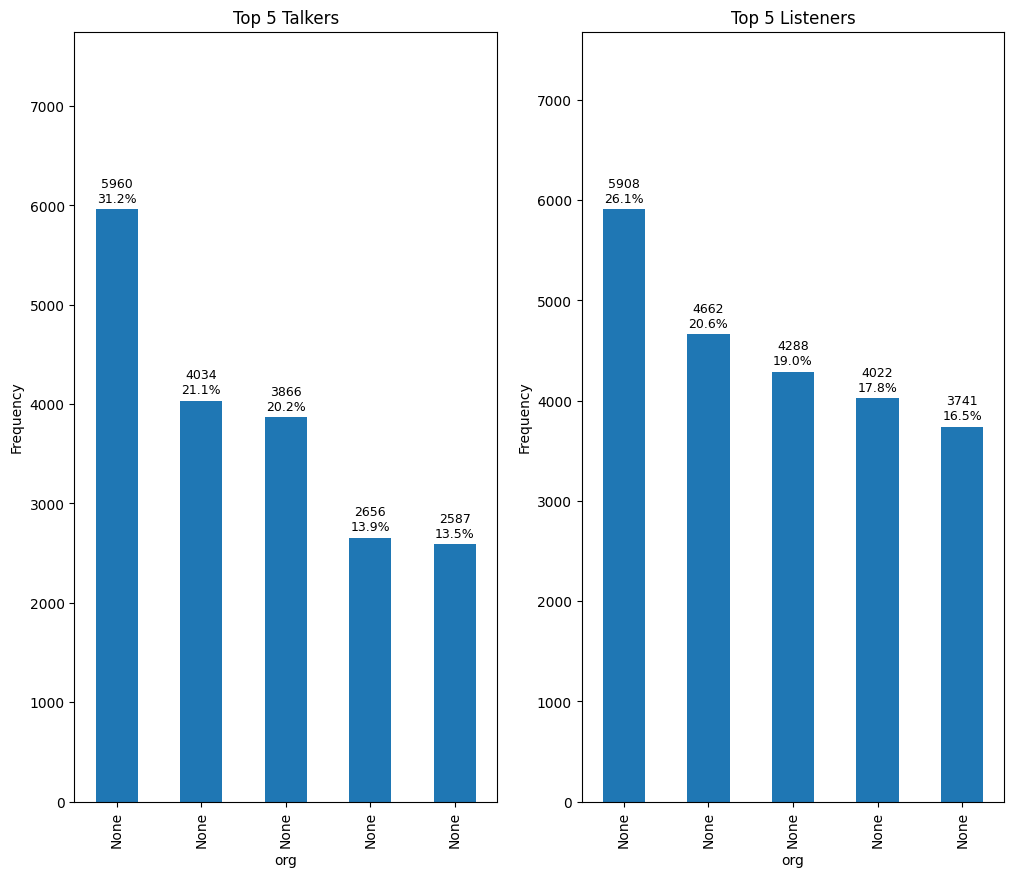

In [78]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 2, figsize=(12, 10)) 

draw_1_var_bar_chart("org", top5_src, aggregated= True, ax = axes[0], count_col= "count", title = "Top 5 Talkers", rot = 90)
draw_1_var_bar_chart("org", top5_dst, aggregated= True, ax = axes[1], count_col= "count", title = "Top 5 Listeners", rot = 90)

------------------------------------

# Exercise 4B: Transport Protocol

In [79]:
top_protocol = df_data_2["tcp6_udp17"].value_counts().reset_index()
top_protocol["tcp6_udp17"].name = "Header value"
top_protocol["Transport layer protocol"] = top_protocol["tcp6_udp17"].map({
    "0": "HOPOPT",
    "1": "ICMP",
    "2": "IGMP",
    "6": "TCP",
    "17": "UDP",
    "41": "IPv6",
    "47": "GRE",
    "50": "ESP",
    "58": "IPv6-ICMP"
}).fillna("other")

# Reorder columns so 'count' comes last
cols = [col for col in top_protocol.columns if col != "count"] + ["count"]
top_protocol = top_protocol[cols]
top_protocol.index += 1

display(top_protocol)

,tcp6_udp17,Transport layer protocol,count
1,6,TCP,137707
2,17,UDP,36852
3,0,HOPOPT,1216
4,50,ESP,718
5,47,GRE,664
6,1,ICMP,60
7,58,IPv6-ICMP,10
8,41,IPv6,3
9,2,IGMP,2


### Extra: Graphs of frequency

<Axes: title={'center': 'Protocol Number by Frequency'}, xlabel='tcp6_udp17', ylabel='Frequency'>

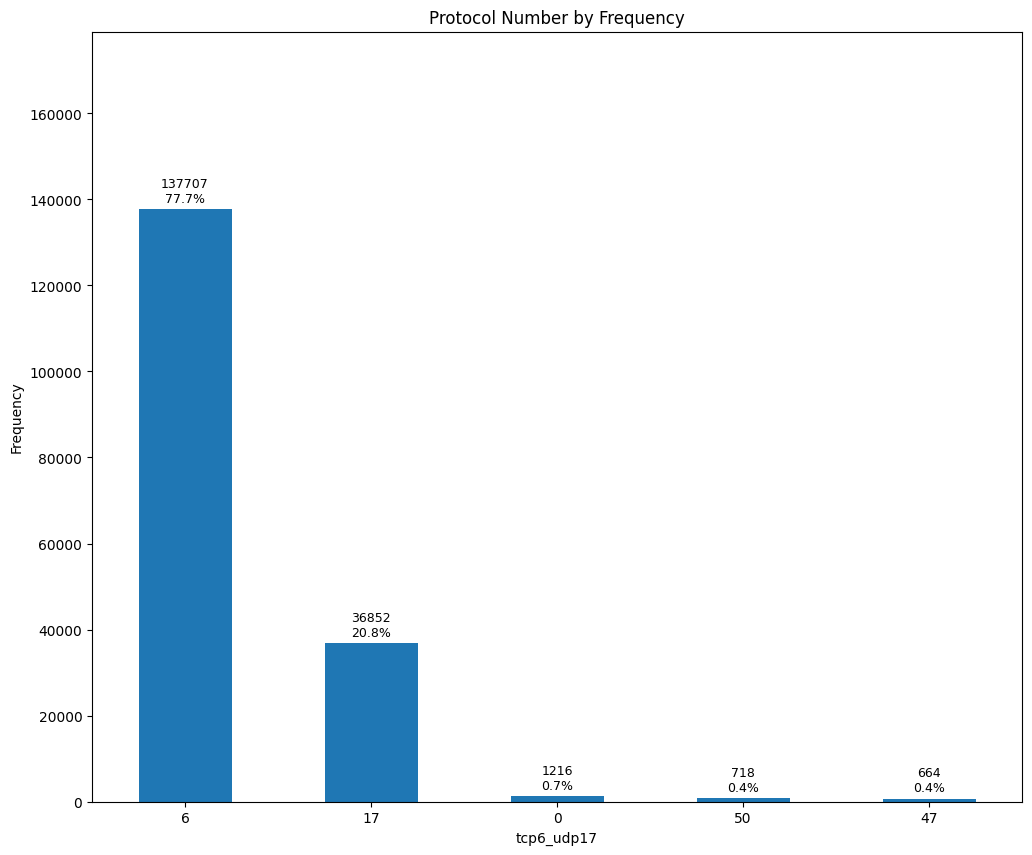

In [80]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 1, figsize=(12, 10)) 

draw_1_var_bar_chart("tcp6_udp17", top_protocol, aggregated= True, ax = axes, count_col= "count", title = "Protocol Number by Frequency", rot = 0)

### Ports

In [81]:
port_number_df = df_data_2["dst_port"].value_counts().reset_index()
port_number_df.index += 1
port_number_df["service"] = pd.to_numeric(port_number_df["dst_port"], errors="raise").map(PORT_APP_MAP).fillna("other")
display(port_number_df.head())

,dst_port,count,service
1,130,50801,cisco-fna
2,193,32369,srmp
3,3,18133,compressnet
4,21,11826,FTP-Control
5,199,11076,smux


### Extra: Graphing Frequency

<Axes: title={'center': 'Top 5 applications'}, xlabel='service', ylabel='Frequency'>

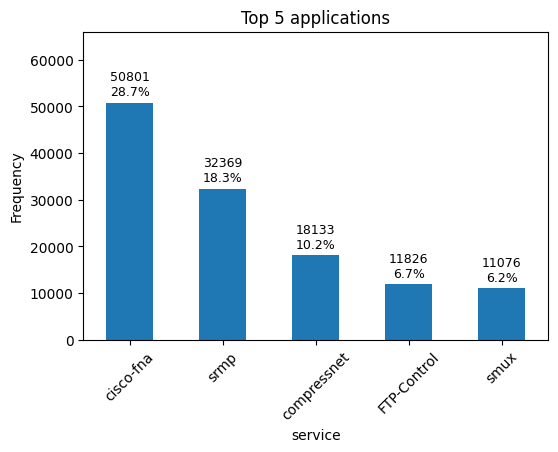

In [82]:
draw_1_var_bar_chart("service", df=port_number_df, title = "Top 5 applications", aggregated= True, count_col= "count")

Extra: Transmission with destination port = 1073741823

In [83]:
# Investigating the forbidden 1073741823 port seen in data
forbidden_port_df = df_data_2[
    (df_data_2["dst_port"] == 1073741823) |
    (df_data_2["dst_port"] == "1073741823") |
    (df_data_2["src_port"] == 1073741823) |
    (df_data_2["src_port"] == "1073741823")
]
display(forbidden_port_df)

# honestly cant find any pattern other than adst mac often cc4e249c6300. 
# cc4e249c6300 works on IBM System Resource Controller or cisco network control/management traffic
# though src_ip = "-" and dst_ip = "-" looks funny

,flow,agent_ip,src_port,dst_port,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,src_ip,dst_ip,tcp6_udp17,ip_type_of_service,ip_time_to_live,src_port_transport_level,dst_port_transport_level,tcp_flags,packet_size,ip_size,sampling_rate
8657,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,221.204.226.22,202.179.249.58,1,0x00,43,8,0,0x00,106,84,2048
34085,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,130,108,2048
41777,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,151,129,2048
81444,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,112.29.150.31,202.179.249.58,1,0x04,43,8,0,0x10,106,84,2048
82214,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,82,60,2048
85753,FLOW,203.30.38.251,21,1073741823,6c9ced25f6bb,ffffffffffff,0x0806,2121,2121,123.136.64.7,74.125.68.108,6,0x00,59,31035,993,0x18,64,46,2048
87376,FLOW,203.30.38.251,129,1073741823,64f69dd64b9e,01000ccccccd,0x0000,1800,1800,-,-,0,0x00,0,0,0,0x00,72,64,2048
104371,FLOW,203.30.38.251,199,1073741823,544b8cf9a7df,cc4e249c6300,0x0800,600,600,202.179.248.2,203.30.38.252,6,0xc0,63,54659,639,0x18,466,444,2048
107386,FLOW,203.30.38.251,21,1073741823,001c739c3a1a,cc4e249c6314,0x0806,2121,2121,117.121.249.253,123.136.64.7,6,0x00,58,80,55192,0x10,64,46,2048
119107,FLOW,203.30.38.251,21,1073741823,cc4e249b8a00,ffffffffffff,0x0806,2121,2121,103.10.124.69,202.21.158.12,6,0x00,126,80,23177,0x10,64,46,2048


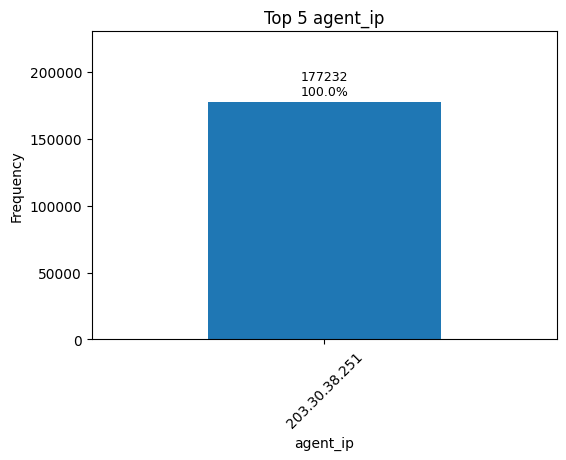

In [84]:
# well thats underwhelming ig Agent IP is SINGAREN so this data is Collected within SINGAREN
draw_1_var_bar_chart("agent_ip",df_data_2)
get_ip_details("203.30.38.251")

In [85]:
# Investigating funny src_ip = "-" and dst_ip = "-"

no_ip_df = df_data_2[
    (df_data_2["src_ip"] == "-") &
    (df_data_2["dst_ip"] == "-")
]
display(no_ip_df)
# well i guess its just that one singular transmission??

,flow,agent_ip,src_port,dst_port,src_mac,dst_mac,ethernet_type,dst_vlan,src_vlan,src_ip,dst_ip,tcp6_udp17,ip_type_of_service,ip_time_to_live,src_port_transport_level,dst_port_transport_level,tcp_flags,packet_size,ip_size,sampling_rate
87376,FLOW,203.30.38.251,129,1073741823,64f69dd64b9e,01000ccccccd,0x0000,1800,1800,-,-,0,0x00,0,0,0,0x00,72,64,2048


To the src_ip = "-" and dst_ip = "-" mystery:

GPT says:

Header truncation (most common)
sFlow samples only the first N bytes of the packet. If N is too small and the capture truncated before the IPv4/IPv6 header (for example because of VLAN/MPLS tags or large L2 header), the collector will show L2 fields (MACs) but no IPs.

Non-IP / L2-only traffic
The sampled packet could be a purely Layer-2 frame (e.g., certain control frames, some tunneled L2 traffic) so there is no IP header to parse.

Encapsulation / tunneling (VXLAN, GRE, IP-in-IP, MPLS)
The visible header may be an outer header the collector doesn’t parse to reach the inner IP header. If the inner packet carried the IPs, but the exporter didn’t decapsulate (or the sample truncated before the inner header), the collector will show no IPs.

Malformed or corrupted sample
The sampled bytes might be corrupted or mis-aligned so the parser fails to locate IP header fields.

Exporter/parser bug or mismatched format
The device exporting sFlow may send fields in a way your collector/parser doesn’t expect (different sFlow version, vendor-specific layout), so the collector can extract MACs but not IPs.

Privacy/anonymization or deliberate redaction
Some exporters can be configured to omit IP addresses for privacy — you’d still see agent and L2 fields.

NAT / offload / hardware acceleration
In some hardware offload scenarios the flow recorder sees frames with non-standard fields (or only flow metadata) and not full IP headers.

Value parsing weirdness
Odd field values (e.g. ethernet_type = 0x0000 or dst port = 1073741823) suggest parsing/mapping problems — the collector may be misinterpreting bytes as ports/ethertype.

# Exercise 4D: Traffic

In [86]:
df_traffic = df_data_2.copy()
df_traffic["ip_size"] = pd.to_numeric(df_traffic["ip_size"], errors="raise")
df_traffic["sampling_rate"] = pd.to_numeric(df_traffic["sampling_rate"], errors="raise")
df_traffic["total_bytes"] = df_traffic["ip_size"] * df_traffic["sampling_rate"]

total_bytes = df_traffic["total_bytes"].sum()

print(f"Estimated total traffic (bytes): {total_bytes}")
print(f"In MB: {total_bytes / (1024**2):.2f} MiB")
print(f"In GB: {total_bytes / (1024**3):.2f} GiB")

Estimated total traffic (bytes): 348026368000
In MB: 331903.81 MiB
In GB: 324.12 GiB


# Exercise 4E: Additional Analysis

## 4E1: Top Pairs

In [87]:
# filter here so later the label generation easier
df_traffic = df_traffic[
    (df_traffic["src_ip"].notna()) &
    (df_traffic["dst_ip"].notna()) &
    (df_traffic["src_ip"] != "-") &
    (df_traffic["dst_ip"] != "-")
]
# Here reset index doesnt sort the list since it strips the groups rather than usual strip index of series
top_pairs = df_traffic.groupby(["src_ip", "dst_ip"])["total_bytes"].sum().reset_index()
# so here sort manually
top_pairs.sort_values("total_bytes", ascending=False, inplace=True)
top_pairs = top_pairs[:10]

In [88]:
top_pairs

,src_ip,dst_ip,total_bytes
3140,130.14.250.7,103.37.198.100,11486208000
10516,171.67.77.19,192.122.131.36,8153530368
2893,129.99.230.54,137.132.22.74,6071025664
9017,155.69.252.133,138.75.242.36,4531200000
3930,137.132.228.42,137.131.17.212,4493604864
2998,13.107.4.50,210.48.222.13,3714863104
12791,192.170.233.203,202.6.241.101,3647201280
13552,202.21.159.246,104.146.199.27,3289169920
15872,212.219.56.184,137.132.204.235,3085256704
9613,155.69.59.250,175.156.89.102,2900457472


In [90]:
# def generate_row_labels():



# top_pairs["pair"] = top_pairs.apply(
#     lambda row: get_ip_details(row["src_ip"], get_organisation=True) 
#                 + " → " 
#                 + get_ip_details(row["dst_ip"], get_organisation=True),
#     axis=1
# )
# print(top_pairs["src_ip"])
# src_org_series = get_ip_details(top_pairs["src_ip"], get_organisation=True)
# dst_org_series = get_ip_details(top_pairs["dst_ip"], get_organisation=True)
# print(src_org_series)
# nd_src_org = np.array(src_org_series)
# nd_dst_org = np.array(dst_org_series)

# for row in range(nd_src_org.shape[0]):
#     if nd_src_org[row] is not None and nd_dst_org[row] is not None: 
#         print(nd_src_org[row])
#         top_pairs[row]["pair"] = nd_src_org[row] + " → " + nd_dst_org[row]
top_pairs["pair"] = get_ip_details(top_pairs["src_ip"], get_organisation=True) + " → " + get_ip_details(top_pairs["dst_ip"], get_organisation=True) # type: ignore

Fetching IP info:   0%|          | 0/10 [00:00<?, ?it/s]

Fetching IP info:   0%|          | 0/10 [00:00<?, ?it/s]

In [96]:
a = get_ip_details(top_pairs["src_ip"], get_organisation=True) 

Fetching IP info:   0%|          | 0/10 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
a

<Axes: title={'center': 'Top 5 pair'}, xlabel='pair', ylabel='Frequency'>

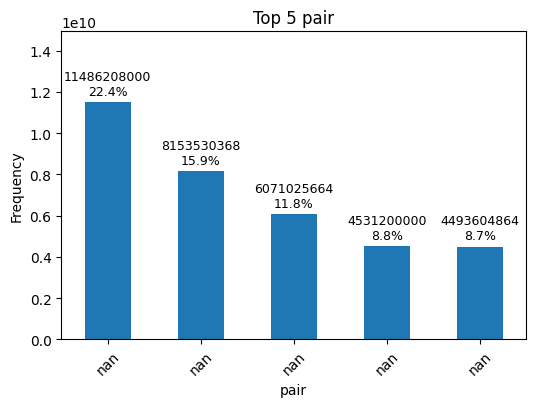

In [ ]:
draw_1_var_bar_chart("pair", top_pairs, count_col="total_bytes", aggregated=True, title = "Top 5 pairs")

## 4E2: Visualising the communication between different IP Hosts

In [92]:
%pip install networkx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [93]:
import networkx as nx

df_filtered = df_data_2[
    (df_data_2["src_ip"].notna()) &
    (df_data_2["dst_ip"].notna()) &
    (df_data_2["src_ip"] != "-") &
    (df_data_2["dst_ip"] != "-")
]

# Step 1: Create directed graph
G = nx.DiGraph()

# Step 2: Add edges with weight = total packets or bytes
for _, row in df_filtered.iterrows():
    src = row["src_ip"]
    dst = row["dst_ip"]
    # Use packet count or estimated bytes
    weight = row["ip_size"] * row["sampling_rate"]  # or row["ip size"] * row["sampling rate"]
    
    if G.has_edge(src, dst):
        G[src][dst]["weight"] += weight
    else:
        G.add_edge(src, dst, weight=weight)

# Step 3: Draw the network
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, k=0.5, iterations=50)  # layout algorithm

# Edge width proportional to weight
edges = G.edges()
weights = [G[u][v]['weight'] / max(1, max(nx.get_edge_attributes(G,'weight').values())) * 10 for u,v in edges]

nx.draw_networkx_nodes(G, pos, node_size=800, node_color='skyblue')
nx.draw_networkx_edges(G, pos, width=weights, alpha=0.6, edge_color='gray', arrows=True)
nx.draw_networkx_labels(G, pos, font_size=10, font_family="sans-serif")

plt.title("IP Communication Network Graph")
plt.axis("off")
plt.show()


TypeError: can't multiply sequence by non-int of type 'str'